In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

# Set the FlowCast project folder
PROJECT_DIR = Path.home() / "Desktop" / "FlowCast"

# Load the cleaned dataset
DATA_PATH = PROJECT_DIR / "data" / "flowcast_traffic_cleaned.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)

# Combine date and time into timestamp
df["timestamp"] = pd.to_datetime(
    df["date"].astype(str) + " " + df["time"].astype(str),
    errors="coerce"
)

# Sort records by road and time
df = df.sort_values(
    ["road_id", "timestamp"]
).reset_index(drop=True)

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (176701, 33)

Missing values:
365977

Column names:
['road_id', 'road_name', 'latitude', 'longitude', 'weather_station_id', 'date', 'time', 'traffic_volume', 'vehicle_count', 'vehicle_type_dist', 'avg_speed', 'occupancy', 'congestion_level', 'travel_time', 'accident_count', 'signal_timing', 'road_capacity', 'datetime', 'weather_hour', 'station_id', 'date_weather', 'time_weather', 'weather_condition', 'temperature', 'rainfall', 'visibility', 'datetime_weather', 'public_holiday', 'holiday_name', 'event_flag', 'event_name', 'roadwork_flag', 'timestamp']

First five rows:


,road_id,road_name,latitude,longitude,weather_station_id,date,time,traffic_volume,vehicle_count,vehicle_type_dist,...,temperature,rainfall,visibility,datetime_weather,public_holiday,holiday_name,event_flag,event_name,roadwork_flag,timestamp
0,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,00:00,97.0,97,"{""2W"": 0.39, ""Car"": 0.35, ""LCV"": 0.12, ""HCV"": ...",...,12.7,0.0,10000.0,2025-01-01 00:00:00,1,New Year's Day,0,NaN,0,2025-01-01 00:00:00
1,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,00:30,99.0,99,"{""2W"": 0.44, ""Car"": 0.34, ""LCV"": 0.11, ""HCV"": ...",...,12.7,0.0,10000.0,2025-01-01 00:00:00,1,New Year's Day,0,NaN,0,2025-01-01 00:30:00
2,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,01:00,102.0,102,"{""2W"": 0.44, ""Car"": 0.43, ""LCV"": 0.06, ""HCV"": ...",...,8.8,0.0,10000.0,2025-01-01 01:00:00,1,New Year's Day,0,NaN,0,2025-01-01 01:00:00
3,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,01:30,113.0,113,"{""2W"": 0.43, ""Car"": 0.36, ""LCV"": 0.09, ""HCV"": ...",...,8.8,0.0,10000.0,2025-01-01 01:00:00,1,New Year's Day,0,NaN,0,2025-01-01 01:30:00
4,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,02:00,92.0,92,"{""2W"": 0.42, ""Car"": 0.39, ""LCV"": 0.09, ""HCV"": ...",...,9.8,0.0,10000.0,2025-01-01 02:00:00,1,New Year's Day,0,NaN,0,2025-01-01 02:00:00


In [2]:
# Extract time-based features from the timestamp

df["hour"] = df["timestamp"].dt.hour
df["minute"] = df["timestamp"].dt.minute
df["day_of_week"] = df["timestamp"].dt.dayofweek
df["day_of_month"] = df["timestamp"].dt.day
df["month"] = df["timestamp"].dt.month

# Weekend indicator: 1 = Saturday/Sunday, 0 = weekday
df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

# Morning and evening peak-hour indicators
df["is_morning_peak"] = (
    df["hour"].between(7, 10)
).astype(int)

df["is_evening_peak"] = (
    df["hour"].between(16, 19)
).astype(int)

# Display the new features
display(
    df[
        [
            "road_id",
            "timestamp",
            "hour",
            "minute",
            "day_of_week",
            "month",
            "is_weekend",
            "is_morning_peak",
            "is_evening_peak"
        ]
    ].head(10)
)

print("Time-based features created successfully!")

,road_id,timestamp,hour,minute,day_of_week,month,is_weekend,is_morning_peak,is_evening_peak
0,NL-001,2025-01-01 00:00:00,0,0,2,1,0,0,0
1,NL-001,2025-01-01 00:30:00,0,30,2,1,0,0,0
2,NL-001,2025-01-01 01:00:00,1,0,2,1,0,0,0
3,NL-001,2025-01-01 01:30:00,1,30,2,1,0,0,0
4,NL-001,2025-01-01 02:00:00,2,0,2,1,0,0,0
5,NL-001,2025-01-01 02:30:00,2,30,2,1,0,0,0
6,NL-001,2025-01-01 03:00:00,3,0,2,1,0,0,0
7,NL-001,2025-01-01 03:30:00,3,30,2,1,0,0,0
8,NL-001,2025-01-01 04:30:00,4,30,2,1,0,0,0
9,NL-001,2025-01-01 05:00:00,5,0,2,1,0,0,0


Time-based features created successfully!


In [3]:
# Sort by road and timestamp before creating lag features
df = df.sort_values(
    ["road_id", "timestamp"]
).copy()

# Ensure traffic measurements are numeric
df["traffic_volume"] = pd.to_numeric(
    df["traffic_volume"], errors="coerce"
)
df["avg_speed"] = pd.to_numeric(
    df["avg_speed"], errors="coerce"
)

# Previous traffic readings for each road
df["traffic_volume_lag_1"] = (
    df.groupby("road_id")["traffic_volume"].shift(1)
)

df["traffic_volume_lag_2"] = (
    df.groupby("road_id")["traffic_volume"].shift(2)
)

df["traffic_volume_lag_4"] = (
    df.groupby("road_id")["traffic_volume"].shift(4)
)

# Previous average speeds for each road
df["avg_speed_lag_1"] = (
    df.groupby("road_id")["avg_speed"].shift(1)
)

df["avg_speed_lag_2"] = (
    df.groupby("road_id")["avg_speed"].shift(2)
)

# Rolling averages using past observations only
df["traffic_volume_rolling_mean_4"] = (
    df.groupby("road_id")["traffic_volume"]
      .transform(
          lambda s: s.shift(1).rolling(
              window=4, min_periods=2
          ).mean()
      )
)

df["avg_speed_rolling_mean_4"] = (
    df.groupby("road_id")["avg_speed"]
      .transform(
          lambda s: s.shift(1).rolling(
              window=4, min_periods=2
          ).mean()
      )
)

# Inspect the new features
display(
    df[
        [
            "road_id",
            "timestamp",
            "traffic_volume",
            "traffic_volume_lag_1",
            "traffic_volume_lag_2",
            "traffic_volume_lag_4",
            "avg_speed",
            "avg_speed_lag_1",
            "traffic_volume_rolling_mean_4"
        ]
    ].head(10)
)

print("Lag and rolling features created successfully!")

,road_id,timestamp,traffic_volume,traffic_volume_lag_1,traffic_volume_lag_2,traffic_volume_lag_4,avg_speed,avg_speed_lag_1,traffic_volume_rolling_mean_4
0,NL-001,2025-01-01 00:00:00,97.0,NaN,NaN,NaN,53.0,NaN,NaN
1,NL-001,2025-01-01 00:30:00,99.0,97.0,NaN,NaN,56.7,53.0,NaN
2,NL-001,2025-01-01 01:00:00,102.0,99.0,97.0,NaN,55.7,56.7,98.000000
3,NL-001,2025-01-01 01:30:00,113.0,102.0,99.0,NaN,53.5,55.7,99.333333
4,NL-001,2025-01-01 02:00:00,92.0,113.0,102.0,97.0,53.9,53.5,102.750000
5,NL-001,2025-01-01 02:30:00,103.0,92.0,113.0,99.0,53.9,53.9,101.500000
6,NL-001,2025-01-01 03:00:00,94.0,103.0,92.0,102.0,58.7,53.9,102.500000
7,NL-001,2025-01-01 03:30:00,91.0,94.0,103.0,113.0,53.6,58.7,100.500000
8,NL-001,2025-01-01 04:30:00,104.0,91.0,94.0,92.0,53.3,53.6,95.000000
9,NL-001,2025-01-01 05:00:00,108.0,104.0,91.0,103.0,53.4,53.3,98.000000


Lag and rolling features created successfully!


In [4]:
from pathlib import Path

# Save the feature-engineered dataset
PROJECT_DIR = Path.home() / "Desktop" / "FlowCast"
OUTPUT_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = OUTPUT_DIR / "flowcast_features.csv"

df.to_csv(output_path, index=False)

print("Feature-engineered dataset saved successfully!")
print("File location:", output_path)
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

print("\nNew feature columns:")
print([
    col for col in df.columns
    if "lag" in col or "rolling_mean" in col
])

Feature-engineered dataset saved successfully!
File location: C:\Users\pathi\Desktop\FlowCast\data\processed\flowcast_features.csv
Total rows: 176701
Total columns: 46

New feature columns:
['event_flag', 'roadwork_flag', 'traffic_volume_lag_1', 'traffic_volume_lag_2', 'traffic_volume_lag_4', 'avg_speed_lag_1', 'avg_speed_lag_2', 'traffic_volume_rolling_mean_4', 'avg_speed_rolling_mean_4']


In [5]:
# Check the target and feature columns before model training

print("Dataset shape:", df.shape)

print("\nTraffic prediction target:")
print("traffic_volume" in df.columns)

print("\nAvailable target columns:")
for col in ["traffic_volume", "avg_speed", "congestion_level",
            "travel_time", "accident_count"]:
    if col in df.columns:
        print(f"{col}: available")

print("\nMissing values in important columns:")
important_cols = [
    "traffic_volume",
    "avg_speed",
    "traffic_volume_lag_1",
    "traffic_volume_lag_2",
    "traffic_volume_lag_4",
    "avg_speed_lag_1",
    "traffic_volume_rolling_mean_4",
]

display(df[important_cols].isna().sum().to_frame("missing_values"))

Dataset shape: (176701, 46)

Traffic prediction target:
True

Available target columns:
traffic_volume: available
avg_speed: available
congestion_level: available
travel_time: available
accident_count: available

Missing values in important columns:


,missing_values
traffic_volume,0
avg_speed,0
traffic_volume_lag_1,25
traffic_volume_lag_2,50
traffic_volume_lag_4,100
avg_speed_lag_1,25
traffic_volume_rolling_mean_4,50


In [6]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Sort data chronologically
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
model_df = df.sort_values("timestamp").copy()

# Use only numeric features available at prediction time
feature_cols = [
    "traffic_volume_lag_1",
    "traffic_volume_lag_2",
    "traffic_volume_lag_4",
    "avg_speed_lag_1",
    "avg_speed_lag_2",
    "traffic_volume_rolling_mean_4",
    "avg_speed_rolling_mean_4",
    "hour",
    "minute",
    "day_of_week",
    "month",
    "is_weekend",
    "is_morning_peak",
    "is_evening_peak",
]

# Keep features that exist in the dataset
feature_cols = [c for c in feature_cols if c in model_df.columns]

# Remove rows without a target or required features
model_df = model_df.dropna(
    subset=feature_cols + ["traffic_volume"]
).copy()

# Split by time: first 80% train, last 20% test
model_df = model_df.sort_values("timestamp").reset_index(drop=True)
split_index = int(len(model_df) * 0.8)

train_df = model_df.iloc[:split_index]
test_df = model_df.iloc[split_index:]

X_train = train_df[feature_cols]
y_train = train_df["traffic_volume"]

X_test = test_df[feature_cols]
y_test = test_df["traffic_volume"]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Features used:", feature_cols)

# Train a baseline Random Forest model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

model.fit(X_train, y_train)

# Predict traffic volume
y_pred = model.predict(X_test)

# Evaluate performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# MAPE, safely excluding zero actual values
nonzero = y_test != 0
mape = (
    np.mean(
        np.abs(
            (y_test[nonzero] - y_pred[nonzero])
            / y_test[nonzero]
        )
    ) * 100
    if nonzero.any() else np.nan
)

print("\nRandom Forest — Traffic Volume Results")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")
print(f"MAPE: {mape:.2f}%")

# Show sample predictions
results = pd.DataFrame({
    "timestamp": test_df["timestamp"].values[:10],
    "actual_traffic_volume": y_test.values[:10],
    "predicted_traffic_volume": y_pred[:10]
})

display(results)

Training rows: 141280
Testing rows: 35321
Features used: ['traffic_volume_lag_1', 'traffic_volume_lag_2', 'traffic_volume_lag_4', 'avg_speed_lag_1', 'avg_speed_lag_2', 'traffic_volume_rolling_mean_4', 'avg_speed_rolling_mean_4', 'hour', 'minute', 'day_of_week', 'month', 'is_weekend', 'is_morning_peak', 'is_evening_peak']

Random Forest — Traffic Volume Results
MAE:  42.51
RMSE: 62.13
R²:   0.9526
MAPE: 10.68%


,timestamp,actual_traffic_volume,predicted_traffic_volume
0,2025-05-01 19:00:00,850.0,1002.650506
1,2025-05-01 19:00:00,570.0,545.268444
2,2025-05-01 19:00:00,1168.0,963.349345
3,2025-05-01 19:00:00,1044.0,995.564286
4,2025-05-01 19:00:00,992.0,995.737524
5,2025-05-01 19:00:00,732.0,746.612131
6,2025-05-01 19:00:00,829.0,862.763833
7,2025-05-01 19:00:00,713.0,683.796964
8,2025-05-01 19:00:00,933.0,945.528195
9,2025-05-01 19:00:00,601.0,667.807762


In [7]:
from pathlib import Path
import joblib
import json

# Create a folder for trained models
PROJECT_DIR = Path.home() / "Desktop" / "FlowCast"
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the trained model and its feature list
model_path = MODEL_DIR / "traffic_volume_random_forest.pkl"
joblib.dump(model, model_path)

feature_path = MODEL_DIR / "traffic_volume_features.json"
with open(feature_path, "w", encoding="utf-8") as f:
    json.dump(feature_cols, f, indent=4)

print("Model saved successfully!")
print("Model path:", model_path)
print("Feature list saved:", feature_path)

Model saved successfully!
Model path: C:\Users\pathi\Desktop\FlowCast\models\traffic_volume_random_forest.pkl
Feature list saved: C:\Users\pathi\Desktop\FlowCast\models\traffic_volume_features.json


In [10]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/8.2 MB 25.4 MB/s eta 0:00:01
   ------------------- -------------------- 3.9/8.2 MB 10.7 MB/s eta 0:00:01
   ------------------------------------- -- 7.6/8.2 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 10.8 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 1.6/1.6 MB 12.6 MB/s  0:00:00

   ---------------------------------------- 0/6 [pyparsing]
   ------ --------------------------------- 1/6 [kiwisolver]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   -

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


Top 10 features influencing traffic-volume predictions:


,feature,importance
0,traffic_volume_lag_1,0.879778
7,hour,0.038376
2,traffic_volume_lag_4,0.020253
6,avg_speed_rolling_mean_4,0.014065
5,traffic_volume_rolling_mean_4,0.013181
1,traffic_volume_lag_2,0.008450
3,avg_speed_lag_1,0.007533
4,avg_speed_lag_2,0.004880
9,day_of_week,0.003991
8,minute,0.003359


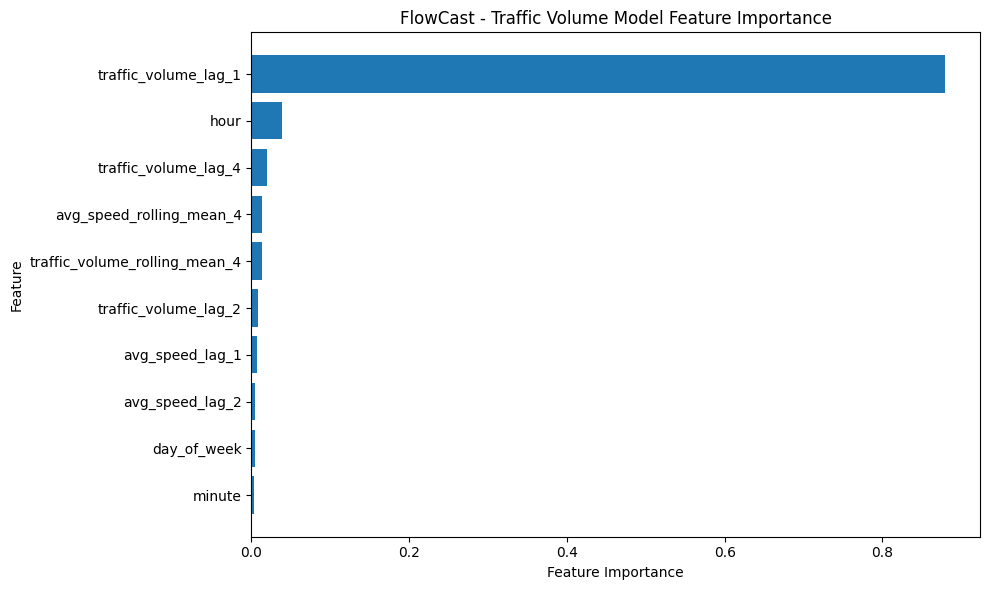

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from the trained Random Forest
importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

print("Top 10 features influencing traffic-volume predictions:")
display(importance_df.head(10))

# Plot the top 10 features
top_features = importance_df.head(10).sort_values("importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("FlowCast - Traffic Volume Model Feature Importance")
plt.tight_layout()
plt.show()

In [3]:
from pathlib import Path
import json
import joblib
import pandas as pd

PROJECT_DIR = Path.home() / "Desktop" / "FlowCast"

# Check saved files
files = [
    PROJECT_DIR / "data" / "processed" / "flowcast_features.csv",
    PROJECT_DIR / "models" / "traffic_volume_random_forest.pkl",
    PROJECT_DIR / "models" / "traffic_volume_features.json"
]

for file in files:
    print(file.name, "EXISTS" if file.exists() else "MISSING")

# Check model and features
model = joblib.load(files[1])

with open(files[2], "r", encoding="utf-8") as f:
    features = json.load(f)

print("\nModel feature count:", model.n_features_in_)
print("Saved feature count:", len(features))
print("Features:", features)

flowcast_features.csv EXISTS
traffic_volume_random_forest.pkl EXISTS
traffic_volume_features.json EXISTS

Model feature count: 14
Saved feature count: 14
Features: ['traffic_volume_lag_1', 'traffic_volume_lag_2', 'traffic_volume_lag_4', 'avg_speed_lag_1', 'avg_speed_lag_2', 'traffic_volume_rolling_mean_4', 'avg_speed_rolling_mean_4', 'hour', 'minute', 'day_of_week', 'month', 'is_weekend', 'is_morning_peak', 'is_evening_peak']
